# **Final Project** - Product Classification and Clustering*by Amanda Ang*


**Background**

The company dataset I will explore in this project is from PriceRunner. PriceRunner is an independent price comparison service that helps shoppers find better products and cheaper prices in order to make smart decisions and save money. It was founded in 1999 and is active in Sweden, the UK, Denmark, and Norway, however, it also includes shipping from foreign countries. They have over 5.8 million products and 15.4 million visits every month in all countries. The dataset was collected from the UC Irvine Machine Learning. UCI Machine Learning Repository is a collection of databases, data generators, and domain theories wherein it is widely used by the machine learning community, students, researchers, and educators for the analysis of ML algorithms and gathering machine learning datasets. 

The dataset that will be used in my project is called Product Classification and Clustering, which contains 35,311 product offers or instances and consists of 10 categories, provided by 306 different merchants. According to Akritidis (2020), this dataset is suitable for clustering, classification, entity-matching algorithms, and problems involving text-mining, in the context of product data. The dataset is in a tabular and text format and it shows that there was previous data preprocessing performed such as case folding and punctuation removal on the titles of column 2. It is stated under the variables table that there are no missing values on all 7 features in the dataset. The variables include Product ID, Product Title, Merchant ID, Cluster ID, Cluster Label, Category ID, and Category Label. 

Sources: About PriceRunner. (2022) [Online] PriceRunner United Kingdom. Available from: https://www.pricerunner.com/info/about-pricerunner
Akritidis, L. (2020). Product Classification and Clustering [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5M91Z.
UCI Machine Learning Repository. (2019) [Online] Uci.edu. Available from: https://archive.ics.uci.edu/ 




In [8]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns  
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import datasets, metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from sklearn.cluster import KMeans
from collections import Counter
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, classification_report, accuracy_score, ConfusionMatrixDisplay
from scipy.stats import ks_2samp

The first imperative step in every data analysis process is to import the essential libraries like Seaborn, Pandas, Numpy, and Matplotlib, which are generally used for data manipulation, visualisation, general plotting, and numerical computation. Additionally, libraries like 'sklearn', involves machine learning algorithms including 'KNeighborsClassifier', 'RandomForestClassifier', 'Logistic Regression' and more, are also important. These libraries are crucial in later code blocks for exploratory data analysis and machine learning, both classification and clustering.

## Exploratory Data Analysis (EDA)

In [11]:
df = pd.read_csv("C:\\Users\\amand\\Downloads\\YEAR 2\\Term 2\\pricerunner_aggregate.csv")

Second, executing the 'pd.read_csv' function of Pandas will allow the program to read the PriceRunner dataset or the CSV file. 

In [13]:
df.shape

(35311, 7)

The '.shape' attributes of Numpy shows the number of rows and columns respectively. It displays that there are 35,311 rows and 7 columns overall. 

In [15]:
df.head()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


The '.head()' method of Pandas presents the top 5 rows of the dataset, which provides a quick glance at the dataset. It is observed that each row in the dataset represents a product offer, along with its merchant provider and the category it belongs to. At this initial glance, it is seen that the dataset includes mobile phones and possibly other types of consumer electronics. Each product offer is assigned a unique 'Product ID', while 'Merchant ID', 'Cluster ID' and 'Category ID' depend on the details and grouping of the product. I can consider this dataset to be product-related data that can be extracted for further analysis.

In [17]:
df.dtypes

Product ID          int64
Product Title      object
 Merchant ID        int64
 Cluster ID         int64
 Cluster Label     object
 Category ID        int64
 Category Label    object
dtype: object

With the '.dtypes' object of Numpy, I can identify the type of data each column contains. The columns 'Product ID', 'Merchant ID', 'Cluster ID', and 'Category ID' are 'int64' type which means it stores whole numbers. Meanwhile, 'Product Title', 'Cluster Label', and 'Category Label' is 'object' type that deals with string or mixed data types.

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Product ID       35311 non-null  int64 
 1   Product Title    35311 non-null  object
 2    Merchant ID     35311 non-null  int64 
 3    Cluster ID      35311 non-null  int64 
 4    Cluster Label   35311 non-null  object
 5    Category ID     35311 non-null  int64 
 6    Category Label  35311 non-null  object
dtypes: int64(4), object(3)
memory usage: 1.9+ MB


The '.info' function of Pandas lays out a summary for each column in the DataFrame, including ist column name, non-null count, data type, and the total number of entries. There are a total of 35,311 entries, with an index starting at 0. It is apparent that all of the columns do not have any missing values, which makes it advantageous for data analysis and eliminates the need for extensive data cleaning.

In [21]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product ID,35311.0,NaN,NaN,NaN,26150.800176,13498.19122,1.0,14958.5,27614.0,37508.5,47358.0
Product Title,35311,30993,washing machine,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Merchant ID,35311.0,NaN,NaN,NaN,120.501883,117.045557,1.0,17.0,75.0,253.0,371.0
Cluster ID,35311.0,NaN,NaN,NaN,30110.687633,18410.265642,1.0,6123.0,40630.0,44059.0,47525.0
Cluster Label,35311,12849,Canon IXUS 185,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category ID,35311.0,NaN,NaN,NaN,2618.14293,3.600708,2612.0,2615.0,2619.0,2622.0,2623.0
Category Label,35311,10,Fridge Freezers,5501,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The '.describe' method is utilized for providing summary statistics of the DataFrame. It reveals that there are 30,993 unique product titles, with "washing machine" being the most frequent, appearing 90 times. The Product ID would not be relevant to the analysis since its a unique assignment for each product offering. The maximum value of 'Merchant ID' is 371, which means the IDs range from 1 to 371, with each product offer associated with a merchant. The 'Cluster ID' ranges from 1 to 47,525. On the other hand, there are 12,849 unique 'Cluster Label', with "Canon IXUS 185" being the most frequent label, which appears 27 times. The 'Category ID' ranges closely from 2,612 to 2,623, which means there are few categories but they cover a vast number of product offers. That said, the "Fridge Freezers" is the most frequent category (appeared 5,501 times) in the 'Category Label'.

In [23]:
df.isnull().sum()

Product ID         0
Product Title      0
 Merchant ID       0
 Cluster ID        0
 Cluster Label     0
 Category ID       0
 Category Label    0
dtype: int64

Again, this confirms that none of the columns have missing values.

In [25]:
df.columns = df.columns.str.strip()
print(df.columns)

Index(['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID',
       'Cluster Label', 'Category ID', 'Category Label'],
      dtype='object')


In this code block, I removed the unnecessary space at the beginning of some of the columns through the '.strip()' method to avoid random errors from white spaces in the later code. 

In [27]:
duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")


Number of duplicate rows: 0


I can use the 'duplicated()' and '.sum()' methods to check the total number of duplicated rows. In this case, I don't have any duplicated rows. This means that the PriceRunner dataset already has a solid foundation for data analysis. 

In [29]:
df

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
...,...,...,...,...,...,...,...
35306,47350,smeg fab28 60cm retro style right hand hinge f...,59,47517,Smeg FAB28 Cream,2623,Fridges
35307,47351,smeg fab28 60cm retro style left hand hinge fr...,59,47518,Smeg FAB28 Red,2623,Fridges
35308,47352,smeg fab28 60cm retro style left hand hinge fr...,59,47519,Smeg FAB28 Pink,2623,Fridges
35309,47355,candy 60cm built under larder fridge cru160nek,125,47524,Candy CRU16.0,2623,Fridges


In [30]:
for i in df.columns:
    print(i,':',df[i].nunique())

Product ID : 35311
Product Title : 30993
Merchant ID : 306
Cluster ID : 13233
Cluster Label : 12849
Category ID : 10
Category Label : 10


This code block displays the number of unique values in  each column. Based on the results, there are 306 unique merchants. There are also 10 unique 'Category ID', which matches with number of unique 'Category Label'.

In [32]:
category_label_mapping = {label: idx for idx, label in enumerate(df['Category Label'].unique())}
print(category_label_mapping)

{'Mobile Phones': 0, 'TVs': 1, 'CPUs': 2, 'Digital Cameras': 3, 'Microwaves': 4, 'Dishwashers': 5, 'Washing Machines': 6, 'Freezers': 7, 'Fridge Freezers': 8, 'Fridges': 9}


To further expound on the 'Category Labels' using mapping and dictionary, I can observe that the categories consist of Mobile Phones, TVs, CPUs, Digital Cameras, Microwaves, Dishwashers, Washing Machines, Freezers, Fridge Freezers, and Fridge, wherein the product offerings are grouped into one of these categories. 

In [34]:
categorical_cols = df.select_dtypes(include=['object']).columns
print("\nCategorical Columns:")
print(categorical_cols)

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("\nNumerical Columns:")
print(numerical_cols)


Categorical Columns:
Index(['Product Title', 'Cluster Label', 'Category Label'], dtype='object')

Numerical Columns:
Index(['Product ID', 'Merchant ID', 'Cluster ID', 'Category ID'], dtype='object')


In this code block, I can see which features belong to categorical and numerical columns. This is crucial for preprocessing data and feature selection when used for analyses and models later on.

***

#### How can we improve product categorization, merchant performance, and overall sales strategy based on product titles, categories, clusters, and merchant behavior?


##### 1.What are the most common 4-word combinations in product titles, and how can they assist in product categorization?


Before proceeding with data visualization, I observed that the most frequent product titles had unusually low values (e.g., 90, 35, 34), despite having over 35,000 entries. Upon cross-checking the CSV file in Excel, I found that "washing machine" appeared 2,540 times, showing the results from Jupyter Notebook were inaccurate. The low count was due to the program matching exact phrases like "washing machine," but not longer descriptions such as "bosch wan28201gb washing machine." I also noticed inconsistencies in the product titles, with extra details, misspellings, and varying word orders. This highlighted the need for extensive standardization. To address this, I created a 4-gram visualization to capture multi-word patterns, providing a more accurate representation by considering word combinations rather than isolated words.

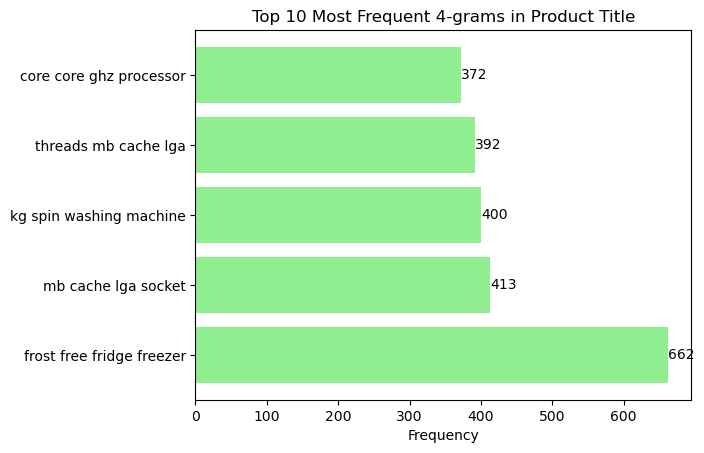

In [40]:
df['processed_titles'] = df['Product Title'].str.lower().replace(r'[^a-z\s]', '', regex=True)

vectorizer = CountVectorizer(ngram_range=(4, 4), stop_words='english')
ngrams = vectorizer.fit_transform(df['processed_titles'])
ngrams_count = ngrams.sum(axis=0).A1
ngram_freq = dict(zip(vectorizer.get_feature_names_out(), ngrams_count))

top_ngrams = dict(sorted(ngram_freq.items(), key=lambda item: item[1], reverse=True)[:5])

plt.barh(list(top_ngrams.keys()), list(top_ngrams.values()), color='lightgreen')
for index, value in enumerate(top_ngrams.values()):
    plt.text(value, index, str(value), va='center', ha='left', fontsize=10, color='black')

plt.xlabel('Frequency')
plt.title('Top 10 Most Frequent 4-grams in Product Title')
plt.show()

It is evident that “frost-free fridge freezer” appears most frequently in the dataset, with 662 occurrences. Next are “mb cache lga socket”, “kg spin washing machine”, “threads mb cache lga”, and “core ghz processor”, wherein the counts are closer to each other. 4-grams can enhance product categorization, especially in identifying important product attributes. I used 4-grams in product titles because it can help me identify the most frequent combinations of terms related to particular product features or types which makes it easier to search. This is more effective than using value.counts() since it provides inaccurate results. I want to determine which product offers occur most frequently in the dataset using keywords. Aside from categorization, 4-grams improves the searchability of the products in the dataset. Overall, this method can assist in grouping relevant products together or facilitate product bundling to encourage upselling. 

##### 2. Which product categories have the most products, and how can we use this for optimization?

C:\Users\amand\AppData\Local\Temp\ipykernel_41912\3995559133.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, y='Category Label', order=df['Category Label'].value_counts().index, palette='pastel')


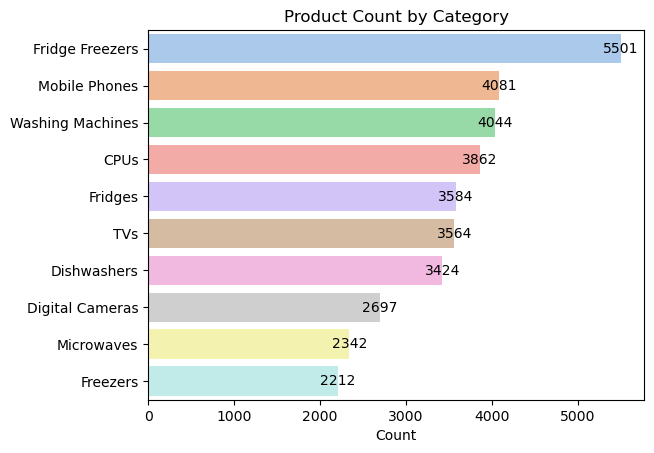

In [43]:
ax = sns.countplot(data=df, y='Category Label', order=df['Category Label'].value_counts().index, palette='pastel')

plt.title('Product Count by Category')
plt.xlabel('Count')

ax.set_ylabel('')  

for p in ax.patches:
    ax.text(p.get_width() + 0.2, p.get_y() + p.get_height() / 2, 
            f'{int(p.get_width())}', 
            ha='center', va='center', fontsize=10, color='black')
plt.show()

The product category with the highest number of products is Fridge Freezers, with a value of 5,501. It has a noticeable difference of more than 1,000 products compared to categories like Mobile Phones, Washing Machines, CPUs, Fridges, etc… The large number of fridge freezer products available implies that the market may be oversaturated, which leads to intense competition with many options for customers to choose from. Therefore, the company can focus on advertising and promoting the top categories, and highlighting these categories depending on the season or demand. The company can create great campaigns for this category like “Top Fridge Freezers of 2025” or “Popular Mobile Phones under £1000”.  Since most of these are high-end products, it is best to improve the comparison features into a more detailed one wherein there are user reviews, ratings, and side-by-side comparisons of specifications. With that, customers can better navigate and understand the different product offerings in the same category. 

##### 3.  What are the most frequent product clusters, and how can clustering boost sales?

C:\Users\amand\AppData\Local\Temp\ipykernel_41912\1053043051.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df[df['Cluster Label'].isin(top_5_clusters.index)],


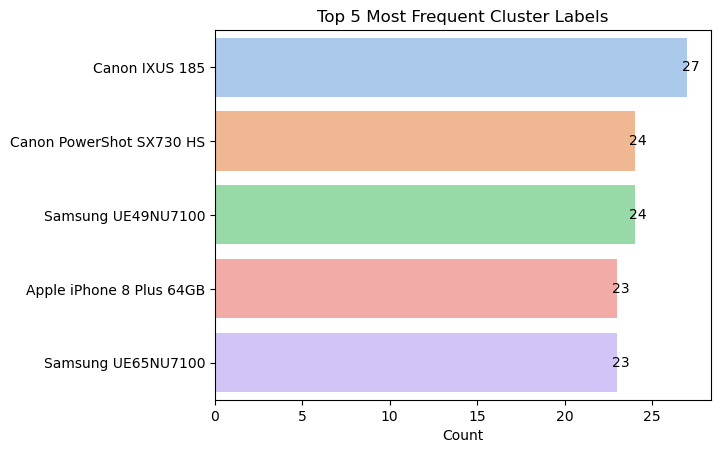

In [46]:
top_5_clusters = df['Cluster Label'].value_counts().nlargest(5)

ax = sns.countplot(data=df[df['Cluster Label'].isin(top_5_clusters.index)], 
                   y='Cluster Label', 
                   order=top_5_clusters.index, 
                   palette='pastel')

plt.title('Top 5 Most Frequent Cluster Labels')
plt.xlabel('Count')
ax.set_ylabel('')  

for p in ax.patches:
    ax.text(p.get_width() + 0.2, p.get_y() + p.get_height() / 2, 
            f'{int(p.get_width())}', 
            ha='center', va='center', fontsize=10, color='black')
plt.show()

The most frequent product cluster is the Canon IXUS 185, with 27 occurrences, followed by the Canon PowerShot, Samsung UE49NU7100, Apple iPhone 8 Plus, and Samsung UE65NU7100, respectively. Canon models show high frequencies of clustering, while Samsung TV models appear in two variants. Clustering is useful for product grouping because the company can put clustered products together in a bundle to create great deals for customers and increase sales. Clusters significantly help in grouping products by their brand, model, features, and price points. It can also improve the recommendation systems of the website by suggesting products within the same cluster to customers based on their searches, browsing, and purchase history. Since Canon IXUS 185, the company can design targeted marketing campaigns like advertising a cluster of Canon products with advertisements that showcase professional use features. Overall, this will enhance the shopping experience of customers. 

##### 4.How do merchants perform across different categories, and how can this information optimize performance?

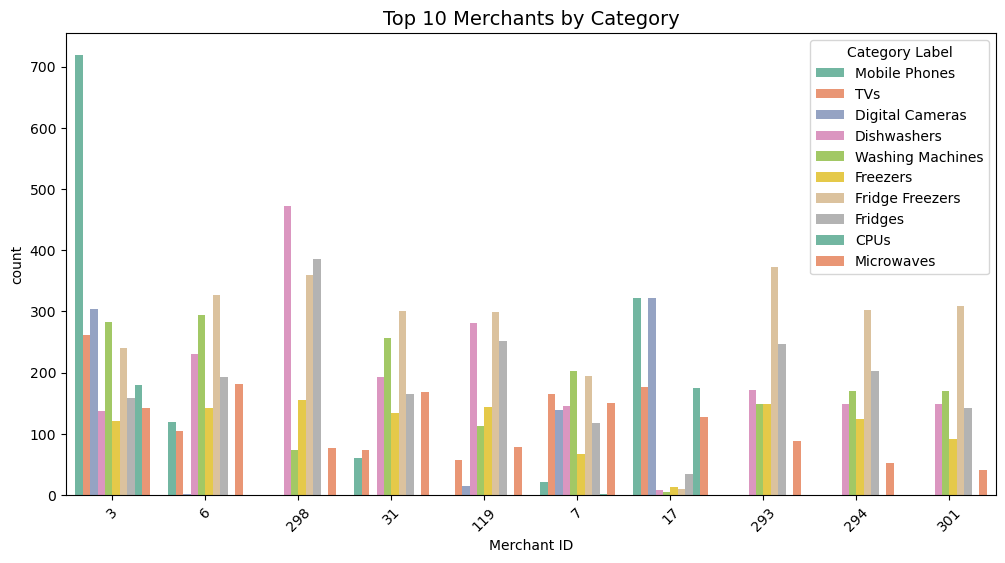

In [49]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='Merchant ID', order=df['Merchant ID'].value_counts().index[:10], hue='Category Label', palette='Set2')
plt.title('Top 10 Merchants by Category', fontsize=14)
plt.xticks(rotation=45)
plt.show()

In [50]:
top_10_merchants = df['Merchant ID'].value_counts().nlargest(10)
print("Top 10 Merchants with the Most Products:")
top_10_merchants

Top 10 Merchants with the Most Products:


Merchant ID
3      2547
6      1591
298    1523
31     1350
119    1239
7      1204
17     1193
293    1177
294    1000
301     901
Name: count, dtype: int64

It is evident that the top-performing merchant is Merchant #3, with a total of 2,547 products. #3 stands out by concentrating on Mobile Phones, with over 700 products, while also offering products from different categories, which shows his diversity. Aside from #3, Merchant #298 is particularly strong in Dishwashers, with over 450 products. I noticed that Fridge Freezers, Freezers, and TVs have a consistent presence across several merchants. Additionally, #17 offers much more for Mobile Phones and Digital Cameras, which focuses on a tech-savvy customer base. The performance can be optimized when merchants focus on their strongest categories and continue to build inventory in these areas. The company can build strong relationships with top merchants and offer them better promotional support and marketing efforts. PriceRunner can also optimize the website interface to make it easy for the shopper to find and compare products of merchants like intuitive navigation and filter options. 

##### 5. Which variables show strong relationships with each other?

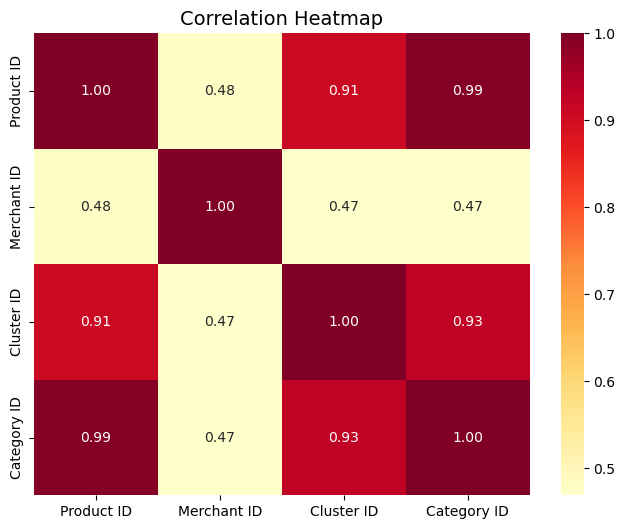

In [76]:
plt.figure(figsize=(8, 6))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='YlOrRd', fmt=".2f")  # Warm colormap
plt.title('Correlation Heatmap', fontsize=14)
plt.show()

It is observed that Product ID and Category ID have a very strong correlation, nearly perfect at 0.99. This suggests that products are nearly aligned with their categories which implies systematic product categorization. Cluster ID and Category ID place the second highest positive correlation, which indicates that clusters are greatly aligned with the product categories. It means that the clustering algorithms are successfully grouping similar products. Lastly, the correlation of 0.91 between Cluster ID and Product ID shows that effective product clustering is based on similar characteristics.

##### Conclusion:

4-grams is useful for product titles because it effectively determines frequent combinations of terms, which helps highlight significant product attributes and categorization accurately. This method also improves upselling and product bundling by grouping relevant products together. Systematic product categorization is seen with a strong correlation between Category ID and Product ID. Merchants must focus on categories they highly concentrate on, while also maintaining an optimal inventory for each item. It is important to build strong relationships with top-performing merchants and provide them with better promotional support. Along with that, the company can enhance product comparison by having detailed review ratings and side-by-side comparisons so customers make better shopping decisions. Clustering enhances the recommendation systems and optimizes the website interface for intuitive navigation. 

## Machine Learning

### Classification

**Model Development and Evaluation**

In [99]:
le = LabelEncoder()
df['Category Label Encoded'] = le.fit_transform(df['Category Label'])

X = df.drop(columns=['Category Label', 'Category Label Encoded', 'Product ID', 'Product Title'])
y = df['Category Label Encoded']

categorical_cols = X.select_dtypes(include=['object']).columns
for col in categorical_cols:
    X[col] = le.fit_transform(X[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) 

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=20)

print(f"Training data shape: {X_train.shape}, Testing data shape: {X_test.shape}")

smote = SMOTE(random_state=20)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

rf_model = RandomForestClassifier(n_estimators=5, max_depth=3, min_samples_split=10, random_state=20, class_weight='balanced')
dt_model = DecisionTreeClassifier(max_depth=6, min_samples_split=10, random_state=20, class_weight='balanced')
kn_model = KNeighborsClassifier(n_neighbors=20) 
lr_model = LogisticRegression(class_weight='balanced', C=400, max_iter=500, solver='liblinear')  

Training data shape: (28248, 5), Testing data shape: (7063, 5)


My target variable is Category Label, so I have to use LabelEncoder to transform categorical labels into numerical values to make it suitable for macihne learning models. I also scale the features using StandardScaler to standardize the data and improve the model performance. I applied SMOTE or Synthetic Minority Over-sampling Technique to balance the class distribution in the tranining set. I splitted the data into 80% (training set) and 20% (testing set) to ensure that the dataset is seperate and is prepared for model evaluation. I'll test into 4 classification models which are the Random Forest, Decision Tree, K-Nearest Neighbors, and Logistic Regression. I adjusted the model configurations appropriately to avoid overfitting and class imbalances, which had happened on my previous predictions. 

In [101]:
def modeling(model_name, model, X_train, y_train, X_test, y_test):
    print(f"\nEvaluating {model_name} Model")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    if hasattr(model, "predict_proba"):
        y_pred_proba = model.predict_proba(X_test)[:, 1] 
    else:
        y_pred_proba = model.decision_function(X_test)
    
    accuracy = accuracy_score(y_test, y_pred) * 100
    error_rate = 100 - accuracy  # Calculate Error Rate
    
    print(f"Accuracy of {model_name}: {accuracy:.2f}%")
    print(f"Error Rate of {model_name}: {error_rate:.2f}%")
    
    print(f"Classification Report for {model_name}:\n{classification_report(y_test, y_pred)}")
    
    cm = confusion_matrix(y_test, y_pred)
    print(f"Confusion Matrix for {model_name}:\n{cm}")
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap="viridis")
    plt.title(f"Confusion Matrix for {model_name}")
    plt.show()

    ks_statistic, ks_p_value = ks_2samp(y_pred_proba[y_test == 0], y_pred_proba[y_test == 1])
    print(f"K-S Statistic for {model_name}: {ks_statistic:.4f}, p-value: {ks_p_value:.4f}")
    
    gini_coefficient = 2 * ks_statistic - 1
    print(f"Gini Coefficient for {model_name}: {gini_coefficient:.4f}")
    
    return accuracy, error_rate, ks_statistic, gini_coefficient, y_pred

I created a function which specifically evaluates machine learning models with various classification metrics like accuracy, error rate, confusion matrix, Gini Coefficient, and K-S statistic to have a detailed report about the model performance. 


Evaluating Random Forest Model
Accuracy of Random Forest: 82.09%
Error Rate of Random Forest: 17.91%
Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.63      0.89      0.74       778
           1       0.45      0.78      0.57       537
           2       0.71      0.47      0.56       690
           3       1.00      1.00      1.00       444
           4       1.00      0.88      0.94      1081
           5       0.85      1.00      0.92       693
           6       1.00      0.26      0.41       472
           7       1.00      1.00      1.00       859
           8       0.89      0.88      0.88       729
           9       1.00      0.83      0.91       780

    accuracy                           0.82      7063
   macro avg       0.85      0.80      0.79      7063
weighted avg       0.86      0.82      0.82      7063

Confusion Matrix for Random Forest:
[[695   0   0   0   0   0   0   0  83   0]
 [119 418   0   0  

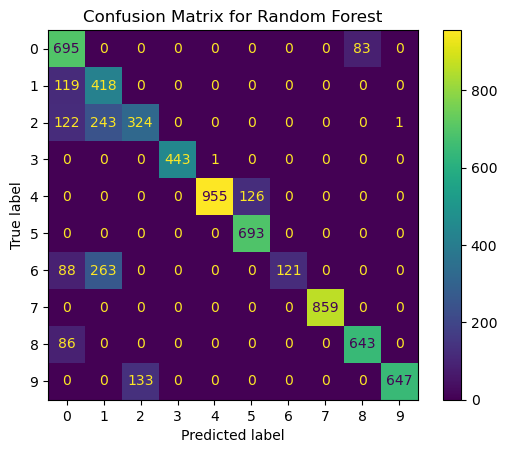

K-S Statistic for Random Forest: 1.0000, p-value: 0.0000
Gini Coefficient for Random Forest: 1.0000

Evaluating Decision Tree Model
Accuracy of Decision Tree: 79.14%
Error Rate of Decision Tree: 20.86%
Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       778
           1       1.00      1.00      1.00       537
           2       1.00      1.00      1.00       690
           3       0.36      1.00      0.53       444
           4       0.61      1.00      0.76      1081
           5       0.00      0.00      0.00       693
           6       1.00      1.00      1.00       472
           7       1.00      1.00      1.00       859
           8       1.00      1.00      1.00       729
           9       0.00      0.00      0.00       780

    accuracy                           0.79      7063
   macro avg       0.70      0.80      0.73      7063
weighted avg       0.69      0.79      0.72      7063

C:\Users\amand\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\amand\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\amand\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


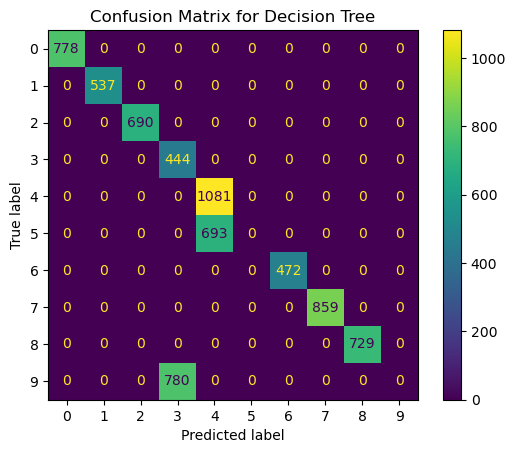

K-S Statistic for Decision Tree: 1.0000, p-value: 0.0000
Gini Coefficient for Decision Tree: 1.0000

Evaluating K-Nearest Neighbors Model
Accuracy of K-Nearest Neighbors: 99.04%
Error Rate of K-Nearest Neighbors: 0.96%
Classification Report for K-Nearest Neighbors:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       778
           1       0.99      0.99      0.99       537
           2       0.99      0.98      0.98       690
           3       0.99      0.98      0.99       444
           4       0.99      1.00      0.99      1081
           5       1.00      0.99      0.99       693
           6       0.97      0.98      0.98       472
           7       1.00      1.00      1.00       859
           8       1.00      0.99      0.99       729
           9       0.98      0.99      0.99       780

    accuracy                           0.99      7063
   macro avg       0.99      0.99      0.99      7063
weighted avg       0.99      0

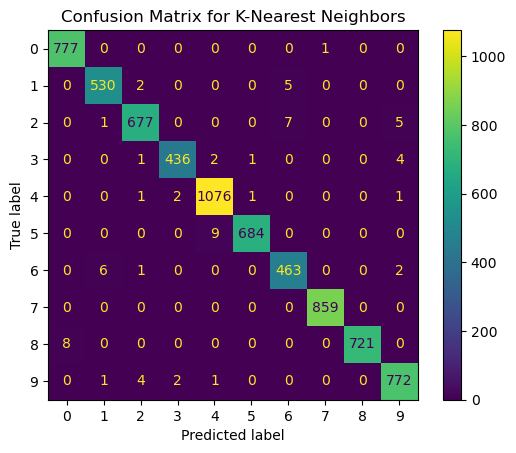

K-S Statistic for K-Nearest Neighbors: 0.9981, p-value: 0.0000
Gini Coefficient for K-Nearest Neighbors: 0.9963

Evaluating Logistic Regression Model
Accuracy of Logistic Regression: 89.71%
Error Rate of Logistic Regression: 10.29%
Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       778
           1       1.00      1.00      1.00       537
           2       0.56      0.62      0.59       690
           3       0.94      0.78      0.85       444
           4       1.00      0.99      0.99      1081
           5       1.00      1.00      1.00       693
           6       0.82      0.73      0.77       472
           7       1.00      1.00      1.00       859
           8       1.00      1.00      1.00       729
           9       0.66      0.71      0.68       780

    accuracy                           0.90      7063
   macro avg       0.90      0.88      0.89      7063
weighted avg     

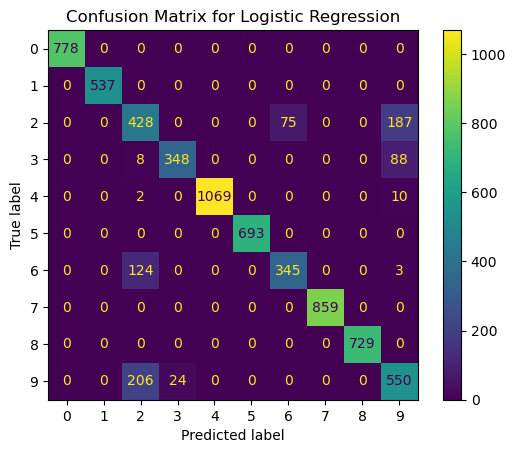

K-S Statistic for Logistic Regression: 1.0000, p-value: 0.0000
Gini Coefficient for Logistic Regression: 1.0000


In [103]:
rf_accuracy, rf_error_rate, rf_ks_stat, rf_gini, rf_ypred = modeling("Random Forest", rf_model, X_train_resampled, y_train_resampled, X_test, y_test)
dt_accuracy, dt_error_rate, dt_ks_stat, dt_gini, dt_ypred = modeling("Decision Tree", dt_model, X_train_resampled, y_train_resampled, X_test, y_test)
kn_accuracy, kn_error_rate, kn_ks_stat, kn_gini, kn_ypred = modeling("K-Nearest Neighbors", kn_model, X_train_resampled, y_train_resampled, X_test, y_test)
lr_accuracy, lr_error_rate, lr_ks_stat, lr_gini, lr_ypred = modeling("Logistic Regression", lr_model, X_train_resampled, y_train_resampled, X_test, y_test)

We then trained and evaluated the models' performance.
* The Random Forest model correctly predicted about 82% of the test data, with approximately 18% of the predictions being incorrect. It achieved perfect recall in classes 3 and 7 but struggled with class 6 (0.26). Overall, it has high accuracy and is effective for classification tasks.
* The Decision Tree model recorded a slightly lower accuracy of 79% and a higher error rate of 21%. While it classified some classes perfectly, it struggled in others where it was unable to predict labels effectively. The Decision Tree's performance may be skewed and not as reliable as other models.
* The KNN model excelled with an exceptionally high accuracy of 99% and an extremely low error rate. Its precision, recall, and F1-scores were consistently high, showing minimal misclassification, which makes this model considerably reliable.
* The Logistic Regression model also achieved high accuracy, around 90%. Despite its lower performance on certain classes, it generally demonstrated robust performance due to its weighted average F1-score. However, it may still face challenges in accurately predicting particular minority classes.

In [146]:
def add_noise(X, noise_factor=0.2):
    noise = np.random.normal(0, noise_factor, X.shape)
    X_noisy = X + noise
    return np.clip(X_noisy, 0, 1)  # Ensure the noisy data is within valid range (0 to 1)

X_train_noisy = add_noise(X_train_resampled)
X_test_noisy = add_noise(X_test)

kn_model = KNeighborsClassifier(n_neighbors=15)

print("Evaluating K-Nearest Neighbors Model with Noise")
kn_model.fit(X_train_noisy, y_train_resampled)
y_pred_noisy = kn_model.predict(X_test_noisy)

accuracy_noisy = accuracy_score(y_test, y_pred_noisy) * 100
print(f"Accuracy of KNN on noisy data: {accuracy_noisy:.2f}%")
print(classification_report(y_test, y_pred_noisy))

Evaluating K-Nearest Neighbors Model with Noise
Accuracy of KNN on noisy data: 52.26%
              precision    recall  f1-score   support

           0       0.66      0.29      0.40       778
           1       0.60      0.78      0.68       537
           2       0.58      0.55      0.57       690
           3       0.34      0.51      0.41       444
           4       0.54      0.39      0.45      1081
           5       0.48      0.60      0.53       693
           6       0.46      0.37      0.41       472
           7       0.45      0.76      0.57       859
           8       0.64      0.52      0.57       729
           9       0.62      0.50      0.56       780

    accuracy                           0.52      7063
   macro avg       0.54      0.53      0.51      7063
weighted avg       0.55      0.52      0.52      7063



Adding noise to the KNN model severely impacted its predictive performance to 52% accuracy. This indicates that this model is highly sensity to noise and may reduce its accuracy and reliability significantly.

**Model Evaluation with and without PCA**

In [ ]:
# Function to train and evaluate models with and without PCA
def evaluate_model_with_pca(model, model_name, X_train, y_train, X_test, y_test, apply_pca=False):
    print(f"Evaluating {model_name} Model (PCA={apply_pca})")
    
    if apply_pca:
        # Apply PCA to reduce dimensions
        pca = PCA(n_components=0.95)  # Retain 95% variance
        X_train_pca = pca.fit_transform(X_train)
        X_test_pca = pca.transform(X_test)
        
        # Train the model on PCA-transformed data
        model.fit(X_train_pca, y_train)
        y_pred = model.predict(X_test_pca)
    else:
        # Train the model on the original data
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred) * 100
    print(f"Accuracy: {accuracy:.2f}%")
    print(classification_report(y_test, y_pred))
    return accuracy, y_pred

# Define models and their names
models = {
    "Random Forest": RandomForestClassifier(n_estimators=5, max_depth=3, min_samples_split=10, random_state=20, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=10, random_state=20, class_weight='balanced'),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=20),
    "Logistic Regression": LogisticRegression(class_weight='balanced', C=400, max_iter=500, solver='liblinear')
}

# Train and evaluate each model with and without PCA
for model_name, model in models.items():
    # Without PCA
    print(f"\n{model_name} Model without PCA:")
    evaluate_model_with_pca(model, model_name, X_train_resampled, y_train_resampled, X_test, y_test, apply_pca=False)

    # With PCA
    print(f"\n{model_name} Model with PCA:")
    evaluate_model_with_pca(model, model_name, X_train_resampled, y_train_resampled, X_test, y_test, apply_pca=True)

I observed that KNN model performs the best in both with or without PCA (both above 99%). Without PCA, Logistic Regression and Random Forest perform well with 89.71% and 82.09% respectively. While Decision Tree performs well without PCA too (>79%). With PCA, the accuracy scores dropped significantly except for the KNN model. This implies that PCA might be discarding important features that are critical for classification in these models. PCA simplifies the data by transforming it into fewer dimensions. These models may depend heavily on feature interactions, which impacted the predictions. 

##### Conclusion:

I realized that the models fail to generalize new data and must have memorized the training set due to the vast capacity to learn the data from it. So adjusting some parameters can help the model generalize better and lead to more realistic accuracy. Increasing the strength of regularization and limiting the complexity of the model really helps with overfitting. I also applied SMOTE since it can help balance class distributions by creating synthetic examples of the minority class which makes the model have better performance and robust.  KNN with PCA is the best model since it effectively captures local patterns in clustered data and reduces noise. 


### Clustering

#### K-Means Clustering

**Elbow Method to Find Optimal k**

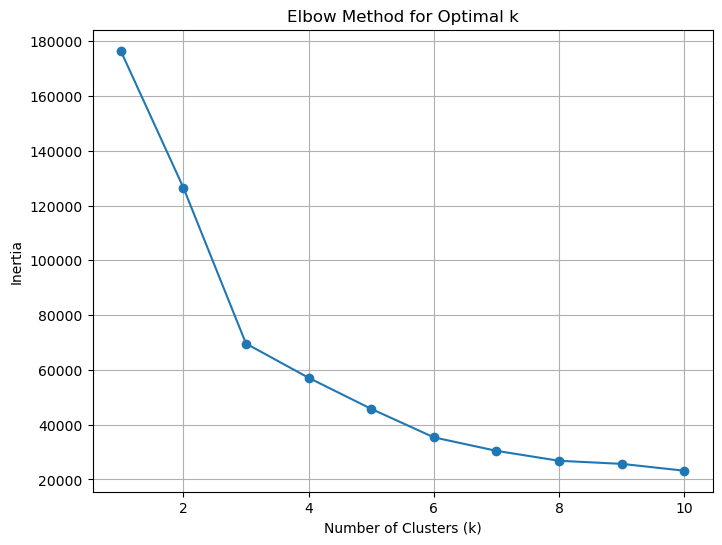

In [202]:
# Elbow Method to find the optimal k
inertia = []
k_range = range(1, 11)  # Try k from 1 to 10

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=20)
    kmeans.fit(X_scaled)  # Use the scaled features
    inertia.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 6))
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

It appears that the elbow point in the graph is 3 clusters or k=3 since it sharply declines in this point or starts to form an elbow. 3 will be the optimal value for k.

In [217]:
# Applying KMeans with the k=3
kmeans_optimal = KMeans(n_clusters=3, random_state=20)
kmeans_labels = kmeans_optimal.fit_predict(X_scaled)

# Add the cluster labels to the dataframe
df['Cluster Label'] = kmeans_labels

# Display the first few rows of the dataframe with cluster labels
df.head()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label,processed_titles,Category Label Encoded
0,1,apple iphone 8 plus 64gb silver,1,1,2,2612,Mobile Phones,apple iphone plus gb silver,7
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,2,2612,Mobile Phones,apple iphone plus gb spacegrau,7
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,2,2612,Mobile Phones,apple mqnba iphone plus gb mp sim free smart...,7
3,4,apple iphone 8 plus 64gb space grey,4,1,2,2612,Mobile Phones,apple iphone plus gb space grey,7
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,2,2612,Mobile Phones,apple iphone plus gold gb g unlocked sim free,7


I applied K-Means with k=3.

In [230]:
# Print the corresponding features after scaling
for i, col in enumerate(df.drop(columns=['Product Title', 'Category Label']).columns): 
    print(f"Feature {i}: {col}")

Feature 0: Product ID
Feature 1: Merchant ID
Feature 2: Cluster ID
Feature 3: Cluster Label
Feature 4: Category ID
Feature 5: processed_titles
Feature 6: Category Label Encoded


In [234]:
print(X.columns)  # This will show you the columns that were selected for scaling

Index(['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID',
       'Cluster Label', 'Category ID', 'Category Label', 'processed_titles',
       'Category Label Encoded'],
      dtype='object')


**Clusters of Elbow Method optimal k (with and Without PCA comparison)**

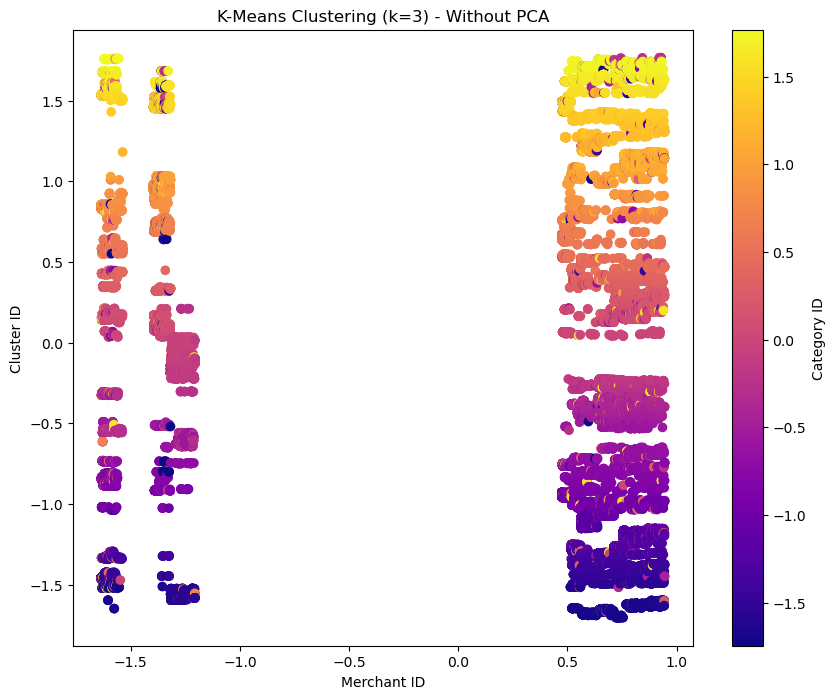

In [276]:
#No PCA
feature_1 = X_scaled[:, 1] 
feature_2 = X_scaled[:, 2]  
feature_3 = X_scaled[:, 4] 

# Plot the clusters using the selected features (Merchant ID, Cluster ID, and Category ID)
plt.figure(figsize=(10, 8))

# Plot with color intensity based on Category ID
scatter = plt.scatter(feature_1, feature_2, c=feature_3, cmap='plasma', marker='o')
plt.title('K-Means Clustering (k=3) - Without PCA')
plt.xlabel('Merchant ID')
plt.ylabel('Cluster ID')

# Colorbar to indicate Category ID
plt.colorbar(scatter, label='Category ID')
plt.show()

Without PCA, the features are directly plotted which means the data is still in its original higher-dimensional space. It includes noise or irrelevant features that makes it complicated for the seperation of clusters and is harder to visualize/analyse. Some features have more variance than others, but since there is no PCA, it is not prioritized. The complexity of the high-dimensional data is not reduced which makes the clusters overlap and harder to distinguish.

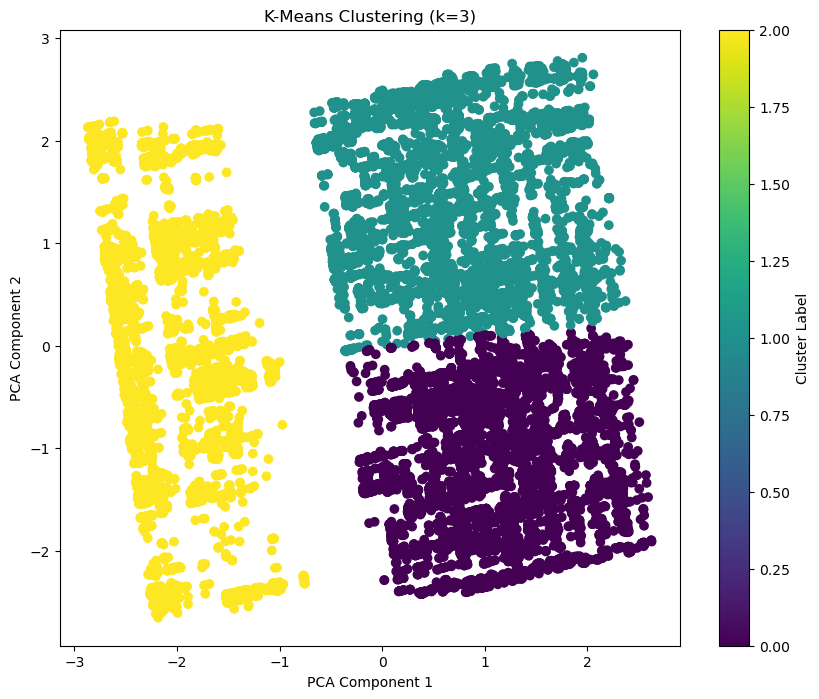

In [238]:
# Reduce dimensions to 2D using PCA
pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled)

# Plot the clusters
plt.figure(figsize=(10, 8))
plt.scatter(pca_components[:, 0], pca_components[:, 1], c=kmeans_labels, cmap='viridis', marker='o')
plt.title(f'K-Means Clustering (k={3})')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster Label')
plt.show()

With PCA, it captures the most variance in the data by identifying the principal components, which filters out the irrelevant features and noise and only highlights the key patterns. It is evident that it provides a clearer seperation between clusters which makes it informative and visually appealing. In short, PCA presents a simplified version of the data by focusing on the important aspects and eliminating the irrelevant information. There are 3 distinct clusters visible which are yellow, teal, and purple. It shows a good vertical, linear seperation. 

In [255]:
# Display the cluster centers
print(f"Cluster centers: \n{kmeans_optimal.cluster_centers_}")

Cluster centers: 
[[ 0.23194692  0.69250075 -0.92378617  0.6303878  -0.91510695]
 [ 0.3888851   0.68499829  0.87321158  0.5829425   0.86900321]
 [-0.64410723 -1.42469048  0.02982281 -1.25438647  0.02535977]]


This represent the "mean" feature values for each cluster

**Silhouette Method to find optimal k**

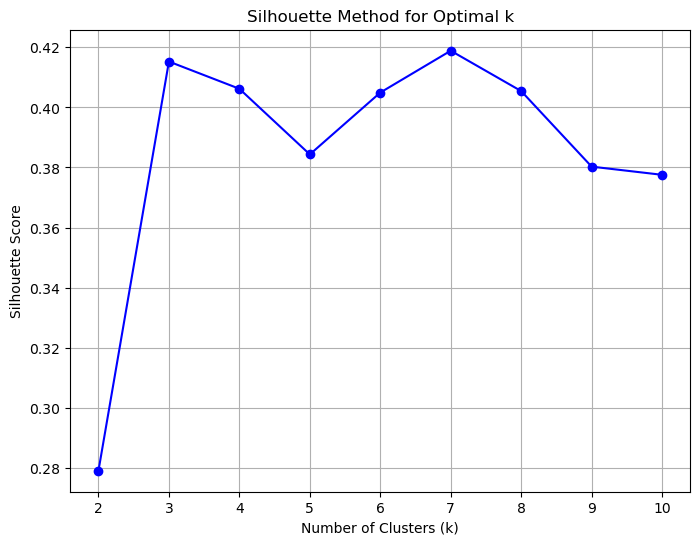

The optimal number of clusters based on the Silhouette Method is k=7


,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label,processed_titles,Category Label Encoded
0,1,apple iphone 8 plus 64gb silver,1,1,4,2612,Mobile Phones,apple iphone plus gb silver,7
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,4,2612,Mobile Phones,apple iphone plus gb spacegrau,7
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,4,2612,Mobile Phones,apple mqnba iphone plus gb mp sim free smart...,7
3,4,apple iphone 8 plus 64gb space grey,4,1,4,2612,Mobile Phones,apple iphone plus gb space grey,7
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,4,2612,Mobile Phones,apple iphone plus gold gb g unlocked sim free,7


In [265]:
# Initialize an empty list to store silhouette scores
silhouette_scores = []

# Try k from 2 to 10, as silhouette score cannot be calculated for k=1
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=20)
    kmeans.fit(X_scaled)  # Use the scaled features
    kmeans_labels = kmeans.labels_
    
    # Calculate silhouette score for the current k
    score = silhouette_score(X_scaled, kmeans_labels)
    silhouette_scores.append(score)

# Plot the Silhouette graph
plt.figure(figsize=(8, 6))
plt.plot(k_range, silhouette_scores, marker='o', color='b')
plt.title('Silhouette Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

# The optimal k is the one that gives the highest silhouette score
optimal_k = k_range[np.argmax(silhouette_scores)]
print(f"The optimal number of clusters based on the Silhouette Method is k={optimal_k}")

# Now apply KMeans with the optimal k
kmeans_optimal = KMeans(n_clusters=optimal_k, random_state=20)
kmeans_labels = kmeans_optimal.fit_predict(X_scaled)

# Add the cluster labels to the dataframe
df['Cluster Label'] = kmeans_labels

# Display the first few rows of the dataframe with cluster labels
df.head()

The highest Silhouette score or peak is k=7 wherein it implies that 7 clusters is the best balance of cluster separation and chesion.

**Clusters of Silhouette Method optimal k (with and Without PCA comparison)**

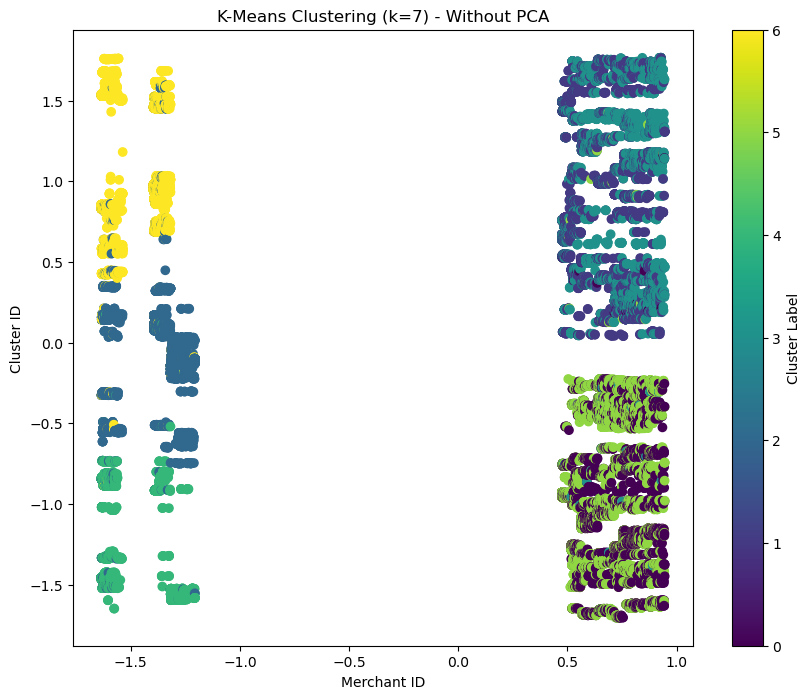

In [281]:
# No PCA
feature_1 = X_scaled[:, 1]  # Merchant ID
feature_2 = X_scaled[:, 2]  # Cluster ID
feature_3 = X_scaled[:, 4]  # Category ID

# Plot the clusters using the selected features
plt.figure(figsize=(10, 8))

# Scatter plot with color indicating the cluster labels
scatter = plt.scatter(feature_1, feature_2, c=kmeans_labels, cmap='viridis', marker='o')

# Adding a colorbar to show the clusters
plt.colorbar(scatter, label='Cluster Label')
plt.title('K-Means Clustering (k=7) - Without PCA')
plt.xlabel('Merchant ID')
plt.ylabel('Cluster ID')
plt.show()

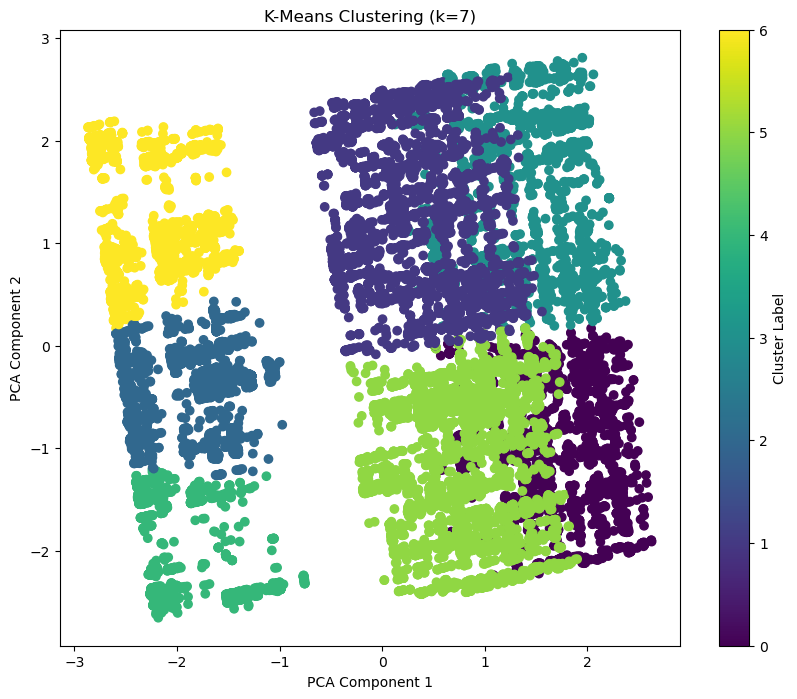

In [269]:
# Reduce dimensions to 2D using PCA
pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled)

# Plot the clusters
plt.figure(figsize=(10, 8))
plt.scatter(pca_components[:, 0], pca_components[:, 1], c=kmeans_labels, cmap='viridis', marker='o')
plt.title(f'K-Means Clustering (k={7})')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster Label')
plt.show()

I noticed it is generally much overlaps or harder to distinguish when PCA is not applied to the clusters on both Elbow and Silhouette method. Meanwhile, PCA is much easier to interpret and much organized clusters.

##### **Conclusion**
It is observed that the silhouette method has a different optimal k compared to the elbow method. The elbow method has an optimal k of 3 while the Silhouette method is 7. Both depends when to use since elbow method focuses on compactness and doesn't consider how well-seperated the clusters are. Meanwhile, the Silhouette Method evaluates both separation and cohesion. But, the elbow method seems more organized while the silhouette method may have closer clusters. K=3 might have a good balance between simplicity and representativeness since it provides a well-defined and distinct cluster. This is ideal for broader product and merchant categories. K=3 is better to use when developing more generalizable and manageable categories. K=7 reveals more detailed and refined insights that may allow for more precise segmentation, but it may seem to overlap. Since k=3 is more organized and the data focuses more on improving product categorization, sales strategy, and product performance, this may be preferable. However, k=7 can provide more detail and is willing to handle the complexity for deeper analysis. 

### Recommendations

* Price Runner must have a systematic product categorization and recommendation systems through clustering and classification to enhance both customer experience and searchability of products. 
* Encourage merchants to concentrate on their strongest categories and diversity in product offerings. 
* Create targeted marketing campaigns for top product categories. 
* The following classification models has its own distinct qualities, however, KNN model is recommended to use due to its high precision. Other models can be used on certain situations. Random Forest for scenarios where high accuracy and balanced performance are required. Decision Trees where model requires interpretability like explaining varying decisions to stakeholders. Logistic Regression for simplicity and general-purpose model.
* Use K=3 (or Elbow Method) for broader categories like general product categorization, inventory management, and overall sales. Meanwhile, K=7 (or Silhouette Method) for in-depth product, merchant analysis, and targeted marketing strategies. 